In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
from google.colab import userdata

token = userdata.get('GITHUB_TOKEN')
repo_dir = '/content/unet-oxford-pets'

if not os.path.exists(repo_dir):
    !git clone -q https://{token}@github.com/slimani-meriem/unet-oxford-pets.git {repo_dir}
else:
    !git -C {repo_dir} pull

%cd {repo_dir}

/content/unet-oxford-pets


In [4]:
!ls
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

00_setup_colab.ipynb.ipynb  LICENSE  README.md	requirements.txt  src
True Tesla T4


### Importing the **OxfordIIITPet** dataset



In [5]:
from torchvision.datasets import OxfordIIITPet
import numpy as np
import matplotlib.pyplot as plt

DATA_ROOT = "/content/data"   # local colab disk

ds = OxfordIIITPet(
    root=DATA_ROOT,
    split="trainval",
    target_types=("category", "segmentation"), # category being a label for one of the 37 pet categories.
    download=True,
)
print("Number of images (trainval) :", len(ds))
print("Number of categories :", len(ds.classes))

100%|██████████| 792M/792M [00:37<00:00, 20.9MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 12.5MB/s]


Number of images (trainval) : 3680
Number of categories : 37


### Inspecting first sample

Image : Image (394, 500) RGB
Mask  : PngImageFile (394, 500) L
Breed : 0 -> Abyssinian
Mask values: {np.uint8(1): np.int64(52806), np.uint8(2): np.int64(114847), np.uint8(3): np.int64(29347)}


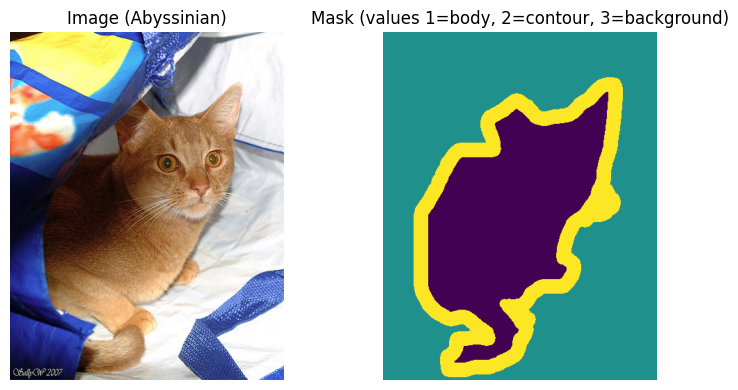

In [6]:
img, (label, mask) = ds[0]

print("Image :", type(img).__name__, img.size, img.mode)  # PIL size = (width, height)
print("Mask  :", type(mask).__name__, mask.size, mask.mode)
print("Breed :", label, "->", ds.classes[label])

values, counts = np.unique(np.array(mask), return_counts=True)
print("Mask values:", dict(zip(values, counts)))


# Display the image and its mask side by side
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img)
axes[0].set_title(f"Image ({ds.classes[label]})")
axes[1].imshow(mask, vmin=1, vmax=3)
axes[1].set_title("Mask (values 1=body, 2=contour, 3=background)")
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

### Do image sizes vary in the dataset?

In [10]:
# test on he first 200 images
sizes = [ds[i][0].size for i in range(200)]
widths, heights = zip(*sizes)
print("Width : min", min(widths), "max", max(widths))
print("Height: min", min(heights), "max", max(heights))

Width : min 119 max 1600
Height: min 174 max 1200


**Obseravtion** : image sizes do vary considerably across the dataset. Images therefore need to be resized to a fixed resolution before being fed to the model, since batches require tensors of identical shape.

### Overlay visualization

An **overlay** draws the segmentation mask semi-transparently on top of the original image. It is useful for several reasons:

- **Checking alignment:** if the mask follows the outline of the animal, the data is correct. This check is essential, especially after resizing or data augmentation, since a misalignment between image and mask would silently ruin training without raising any error.
- **Assessing annotation quality:** it shows where the mask is precise and where it is approximate (fur, ears, paws).
- **Reusability:** during the results analysis, the same technique will be used to overlay the *predicted* mask on the image and see where the model makes mistakes.

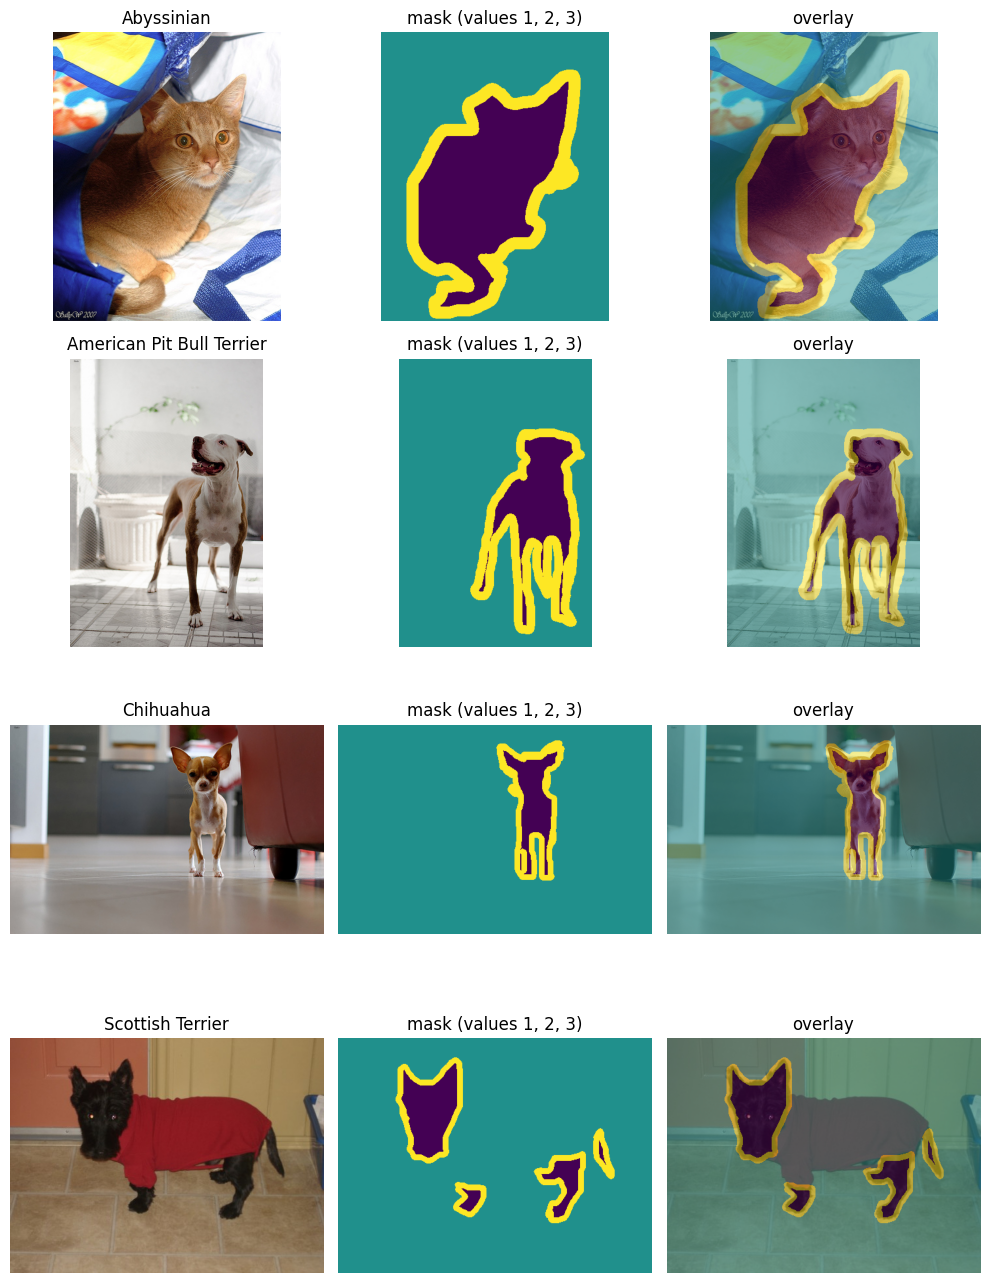

In [7]:
def show_samples(ds, indices):
    fig, axes = plt.subplots(len(indices), 3, figsize=(10, 3.3 * len(indices)))
    for row, i in zip(axes, indices):
        img, (label, mask) = ds[i]
        m = np.array(mask)
        row[0].imshow(img) # displaying the image
        row[0].set_title(ds.classes[label])
        row[1].imshow(m, cmap="viridis", vmin=1, vmax=3) # displaying the mask
        row[1].set_title("mask (values 1, 2, 3)")
        row[2].imshow(img) # displaying the image
        row[2].imshow(m, cmap="viridis", vmin=1, vmax=3, alpha=0.5) # then layering the mask with some opacity
        row[2].set_title("overlay")
        for a in row:
            a.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(ds, [0, 100, 500, 1500])

### Analysing class distribution ?
We analyse the class ditribution in the masks of the dataset.


Understanding class distribution helps guide model training and evaluation.


*   **Evaluation:** Pixel accuracy can be misleading when classes are imbalanced. Metrics such as per-class IoU, mIoU, and Dice provide a more reliable assessment.
*   **Loss function:** Majority classes can dominate the standard cross-entropy loss, causing the model to neglect rare classes. Depending on the observed imbalance, class-weighted cross-entropy, Dice loss, or a combination of both can be tested.

The observed class proportions justify these choices and guide experiments rather than relying on arbitrary decisions.

In [5]:
from torchvision.datasets import OxfordIIITPet
from tqdm.auto import tqdm
import numpy as np

CLASS_NAMES = {1: "Pet", 2: "Background", 3: "Border"}

def class_pixel_counts(dataset):
    """Count the pixels of each mask value over the whole dataset."""

    total = np.zeros(4, dtype=np.int64)
    for i in tqdm(range(len(dataset)), desc="Reading masks"):
        _, mask = dataset[i]
        m = np.array(mask)
        total += np.bincount(m.ravel(), minlength=4) # m.ravel() flattens the 2D m
    return total[1:4]

ds_trainval = OxfordIIITPet(root=DATA_ROOT, split="trainval", target_types="segmentation")
ds_test     = OxfordIIITPet(root=DATA_ROOT, split="test",     target_types="segmentation")

counts = {
    "trainval": class_pixel_counts(ds_trainval),
    "test": class_pixel_counts(ds_test),
}
counts["all"] = counts["trainval"] + counts["test"]

for name, c in counts.items():
    print(f"\n{name}")
    for k, n in zip((1, 2, 3), c):
        print(f"  {CLASS_NAMES[k]}: {n / c.sum() * 100:5.2f} %")

Reading masks:   0%|          | 0/3680 [00:00<?, ?it/s]

Reading masks:   0%|          | 0/3669 [00:00<?, ?it/s]


trainval
  Pet        : 29.17 %
  Background : 59.88 %
  Border     : 10.95 %

test
  Pet        : 29.85 %
  Background : 57.96 %
  Border     : 12.18 %

all
  Pet        : 29.52 %
  Background : 58.91 %
  Border     : 11.58 %
